# AAVSO Report Analysis

Analyzes a VPhot time-series photometry run for one target, using three files it produces:

| File | Contents |
|---|---|
| `..._General.txt` | Tab-delimited per-exposure data: JD, filter, airmass, target/comp/check magnitudes, error, SNR, FWHM, skyglow, max ADU |
| `....txt` | AAVSO extended-format report, untransformed (`TRANS=NO`) — standardized magnitudes from straight differential photometry |
| `..._TA.txt` | AAVSO extended-format report, transformed (`TRANS=YES`) via VPhot's Transform Applier — same observations with color-term correction applied |

Sections: (1) light curves, (2) transformed vs. untransformed comparison, (3) check star quality control, (4) extinction/observation-quality diagnostics, (5) summary.

In [1]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

%matplotlib inline

## Configuration

Set these for the run being analyzed; file names follow VPhot's `AAVSOReport_{STAR}_{FILTER_CODE}_{DATE}[_General|_TA].txt` convention.

In [2]:
DATA_DIR = Path("../../../Documents/astrophotography/Photometry/yzboo")
STAR = "YZ-Boo"
FILTER_CODE = "VRB"
OBS_DATE = "20260814"

general_path = DATA_DIR / f"AAVSOReport_{STAR}_{FILTER_CODE}_{OBS_DATE}_General.txt"
untrans_path = DATA_DIR / f"AAVSOReport_{STAR}_{FILTER_CODE}_{OBS_DATE}.txt"
trans_path = DATA_DIR / f"AAVSOReport_{STAR}_{FILTER_CODE}_{OBS_DATE}_TA.txt"

for p in (general_path, untrans_path, trans_path):
    assert p.exists(), f"missing: {p}"

## Load & Parse

The AAVSO extended format is CSV with `#`-prefixed metadata/comment lines and columns
`NAME,DATE,MAG,MERR,FILT,TRANS,MTYPE,CNAME,CMAG,KNAME,KMAG,AMASS,GROUP,CHART,NOTES`.
`NOTES` packs extra fields as `|KEY=VALUE|KEY=VALUE|...` (`C`=comparison star, `K`=check star, `V`=variable/target).

The `_TA.txt` file additionally comments out each original `NO` line and follows it with the transformed `YES`
line, plus header lines with the transform coefficients (`Tbv`, `Tvr`, `Tb_bv`, ...) used by the Transform Applier.

In [3]:
EXT_COLS = ["NAME", "DATE", "MAG", "MERR", "FILT", "TRANS", "MTYPE", "CNAME", "CMAG",
            "KNAME", "KMAG", "AMASS", "GROUP", "CHART", "NOTES"]
NON_NUMERIC_COLS = {"NAME", "FILT", "TRANS", "MTYPE", "CNAME", "KNAME", "GROUP", "CHART", "NOTES", "COMBO"}
FILTER_ORDER = ["B", "V", "R"]
FILTER_COLORS = {"B": "tab:blue", "V": "tab:green", "R": "tab:red"}
JD_UNIX_EPOCH = 2440587.5


def jd_to_utc(jd_series):
    return pd.to_datetime(jd_series - JD_UNIX_EPOCH, unit="D", origin="unix", utc=True)


def parse_notes(notes):
    fields = {}
    for kv in notes.split("|"):
        if "=" in kv:
            k, v = kv.split("=", 1)
            fields[k] = v
    return fields


def parse_aavso_extended(path):
    """Parse an AAVSO extended-format report into (dataframe, header metadata, transform coefficients)."""
    rows = []
    header = {}
    coeffs = {}
    pending_combo = None
    with open(path) as f:
        for raw_line in f:
            line = raw_line.rstrip("\n")
            if not line:
                continue
            if line.startswith("#"):
                m = re.match(r"^#\s*(T[A-Za-z_]+)\s*=\s*([-\d.]+)\s*,\s*\+/-\s*([\d.]+)", line)
                if m:
                    coeffs[m.group(1)] = (float(m.group(2)), float(m.group(3)))
                    continue
                m2 = re.match(r"^#([A-Z_]+)=(.+)$", line)
                if m2 and "," not in m2.group(1):
                    header[m2.group(1)] = m2.group(2)
                    continue
                m3 = re.match(r"^#\s*(BVR?|VR|BR|BV)\s*,", line)
                if m3:
                    pending_combo = m3.group(1)
                continue
            parts = line.split(",")
            if len(parts) < 15:
                continue
            rec = dict(zip(EXT_COLS, parts[:15]))
            rec.update(parse_notes(rec["NOTES"]))
            rec["COMBO"] = pending_combo
            pending_combo = None
            rows.append(rec)

    df = pd.DataFrame(rows)
    for c in df.columns:
        if c not in NON_NUMERIC_COLS:
            df[c] = pd.to_numeric(df[c], errors="coerce")
    df["UT"] = jd_to_utc(df["DATE"])
    return df, header, coeffs

In [4]:
general_df = pd.read_csv(general_path, sep="\t")
general_df["UT"] = jd_to_utc(general_df["JD"])

untrans_df, untrans_header, _ = parse_aavso_extended(untrans_path)
trans_df, trans_header, coeffs = parse_aavso_extended(trans_path)

# General export's comp/check columns are labeled by AAVSO chart ID; identify them from the report.
comp_id = str(untrans_df["CNAME"].iloc[0])
check_id = str(untrans_df["KNAME"].iloc[0])
rename_map = {general_df.columns[3]: "target_mag"}
rename_map.update({sid: name for sid, name in [(comp_id, "comp_mag"), (check_id, "check_mag")] if sid in general_df.columns})
general_df = general_df.rename(columns=rename_map)
general_df["comp_mag"] = pd.to_numeric(general_df["comp_mag"], errors="coerce")

print(f"General export:    {len(general_df)} rows")
print(f"Untransformed:      {len(untrans_df)} rows")
print(f"Transformed:        {len(trans_df)} rows")
print(f"OBSCODE={untrans_header.get('OBSCODE')}  SOFTWARE={untrans_header.get('SOFTWARE')}  CHART={untrans_df['CHART'].iloc[0]}")
print(f"Comparison star {comp_id} (CREFMAG={untrans_df['CREFMAG'].iloc[0]}), check star {check_id} (KREFMAG={untrans_df['KREFMAG'].iloc[0]})")

General export:    449 rows
Untransformed:      449 rows
Transformed:        449 rows
OBSCODE=WJRA  SOFTWARE=VPhot 4.0.83  CHART=X42985AK
Comparison star 108 (CREFMAG=10.819), check star 111 (KREFMAG=11.076)


## Check Stars

**Avg** = mean magnitude across the session, with **(Δ from catalog)** in parentheses.
<span style="color:#2e7d32">Good</span> · <span style="color:#e65100">Borderline</span> · <span style="color:#c62828">Flag</span> — Std vs. 0.02/0.05 mag thresholds; Δ vs. ±1×/2× KREFERR.

In [5]:
def _mag_color(delta, referr):
    if pd.isna(delta) or pd.isna(referr) or referr == 0:
        return ""
    a = abs(delta)
    if a <= referr:
        return "color: #2e7d32"
    if a <= 2 * referr:
        return "color: #e65100"
    return "color: #c62828"


def _std_color(std):
    if pd.isna(std):
        return ""
    if std < 0.02:
        return "color: #2e7d32"
    if std < 0.05:
        return "color: #e65100"
    return "color: #c62828"


def build_check_star_table(untrans_df, trans_df):
    rows = []
    for filt in FILTER_ORDER:
        u = untrans_df[untrans_df["FILT"] == filt]
        t = trans_df[trans_df["FILT"] == filt]
        refmag = u["KREFMAG"].iloc[0]
        referr = u["KREFERR"].iloc[0]
        avg_before, std_before = u["KMAGSTD"].mean(), u["KMAGSTD"].std()
        avg_after, std_after = t["KMAGTRAN"].mean(), t["KMAGTRAN"].std()
        rows.append({
            "Star": f"{check_id} ({refmag:.3f})", "Filter": filt,
            "avg_before": avg_before, "delta_before": avg_before - refmag, "std_before": std_before,
            "avg_after": avg_after, "delta_after": avg_after - refmag, "std_after": std_after,
            "KREFERR": referr,
        })
    return pd.DataFrame(rows)


check_raw = build_check_star_table(untrans_df, trans_df)

check_display = pd.DataFrame({
    "Star": check_raw["Star"],
    "Filter": check_raw["Filter"],
    "Avg (Before)": [f"{a:.3f} ({d:+.3f})" for a, d in zip(check_raw["avg_before"], check_raw["delta_before"])],
    "Std (Before)": check_raw["std_before"],
    "Avg (After)": [f"{a:.3f} ({d:+.3f})" for a, d in zip(check_raw["avg_after"], check_raw["delta_after"])],
    "Std (After)": check_raw["std_after"],
    "KREFERR": check_raw["KREFERR"],
})

check_style = pd.DataFrame("", index=check_display.index, columns=check_display.columns)
check_style["Avg (Before)"] = [_mag_color(d, e) for d, e in zip(check_raw["delta_before"], check_raw["KREFERR"])]
check_style["Std (Before)"] = [_std_color(s) for s in check_raw["std_before"]]
check_style["Avg (After)"] = [_mag_color(d, e) for d, e in zip(check_raw["delta_after"], check_raw["KREFERR"])]
check_style["Std (After)"] = [_std_color(s) for s in check_raw["std_after"]]

display(
    check_display.style
    .apply(lambda _: check_style, axis=None)
    .hide(axis="index")
    .format({"Std (Before)": "{:.3f}", "Std (After)": "{:.3f}", "KREFERR": "{:.3f}"})
)

Star,Filter,Avg (Before),Std (Before),Avg (After),Std (After),KREFERR
111 (11.726),B,11.741 (+0.014),0.013,11.743 (+0.017),0.018,0.050
111 (11.076),V,11.038 (-0.038),0.009,11.037 (-0.039),0.009,0.066
111 (10.658),R,10.615 (-0.043),0.013,10.615 (-0.043),0.016,0.090


## Targets

No catalog magnitude, so only precision is measurable here. **Positive Δ Std** = transform reduced scatter (more precise).

In [6]:
def build_target_table(untrans_df, trans_df):
    rows = []
    for filt in FILTER_ORDER:
        u = untrans_df[untrans_df["FILT"] == filt]
        t = trans_df[trans_df["FILT"] == filt]
        avg_before, std_before = u["MAG"].mean(), u["MAG"].std()
        avg_after, std_after = t["MAG"].mean(), t["MAG"].std()
        rows.append({
            "Filter": filt,
            "Average (Before)": avg_before, "Average (After)": avg_after,
            "Std (Before)": std_before, "Std (After)": std_after,
            "Δ Std": std_before - std_after,
        })
    return pd.DataFrame(rows)


target_table = build_target_table(untrans_df, trans_df)

display(target_table.style.hide(axis="index").format(precision=3, na_rep=""))

Filter,Average (Before),Average (After),Std (Before),Std (After),Δ Std
B,11.008,10.848,0.162,0.179,-0.017
V,10.564,10.580,0.134,0.133,0.002
R,10.313,10.370,0.114,0.108,0.006


## 1. Light Curves

Target magnitude vs. time for each filter, comparing the untransformed and transformed reports.

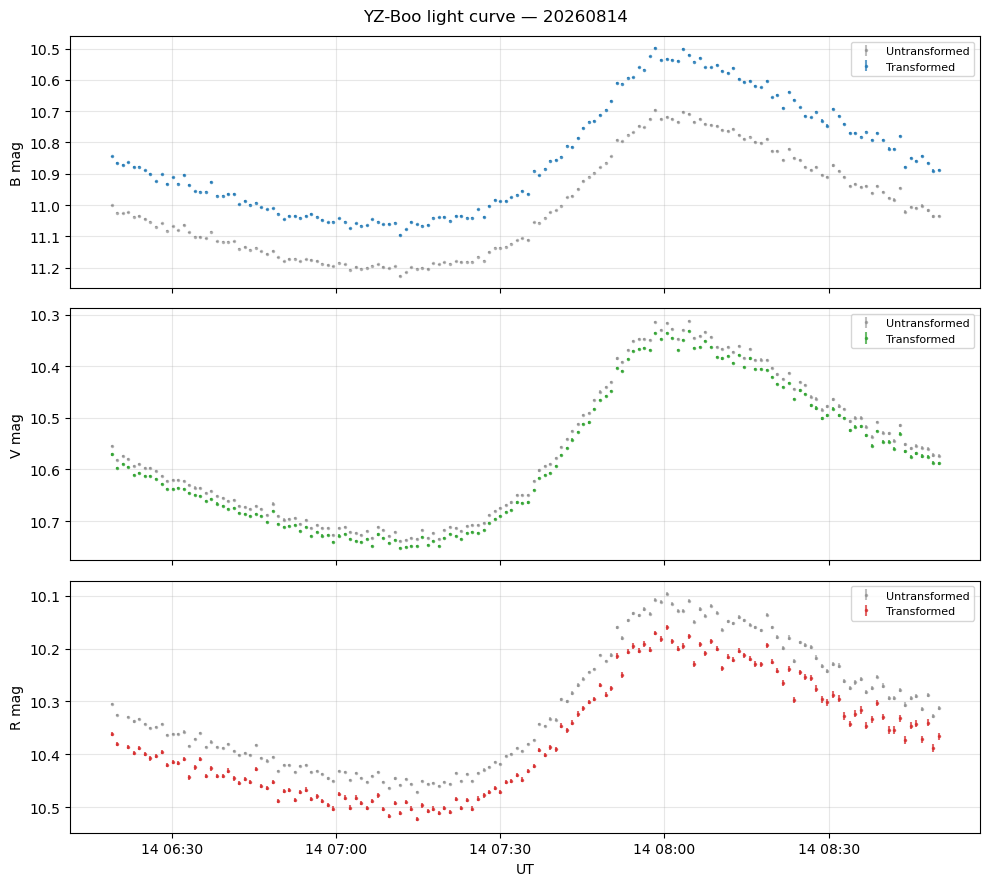

In [7]:
fig, axes = plt.subplots(3, 1, figsize=(10, 9), sharex=True)
for ax, filt in zip(axes, FILTER_ORDER):
    u = untrans_df[untrans_df["FILT"] == filt]
    t = trans_df[trans_df["FILT"] == filt]
    ax.errorbar(u["UT"], u["MAG"], yerr=u["MERR"], fmt=".", ms=3, alpha=0.5, color="gray", label="Untransformed")
    ax.errorbar(t["UT"], t["MAG"], yerr=t["MERR"], fmt=".", ms=3, alpha=0.7, color=FILTER_COLORS[filt], label="Transformed")
    ax.invert_yaxis()
    ax.set_ylabel(f"{filt} mag")
    ax.legend(loc="best", fontsize=8)
    ax.grid(alpha=0.3)
axes[-1].set_xlabel("UT")
fig.suptitle(f"{STAR} light curve — {OBS_DATE}")
fig.tight_layout()

## 2. Transformed vs. Untransformed Comparison

How much the Transform Applier's color-term correction shifted each filter's magnitudes, and how that
correction evolved over the night (it tracks the target's changing brightness/color, not a fixed offset).

In [8]:
merged = pd.merge(untrans_df, trans_df, on=["DATE", "FILT"], suffixes=("_untrans", "_trans"))
merged["diff"] = merged["MAG_trans"] - merged["MAG_untrans"]
diff_stats = merged.groupby("FILT")["diff"].agg(["count", "mean", "std", "min", "max"]).reindex(FILTER_ORDER)
diff_stats

,count,mean,std,min,max
FILT,,,,,
B,150,-0.159160,0.017917,-0.203,-0.131
V,150,0.016060,0.001799,0.013,0.020
R,149,0.056409,0.007459,0.044,0.080


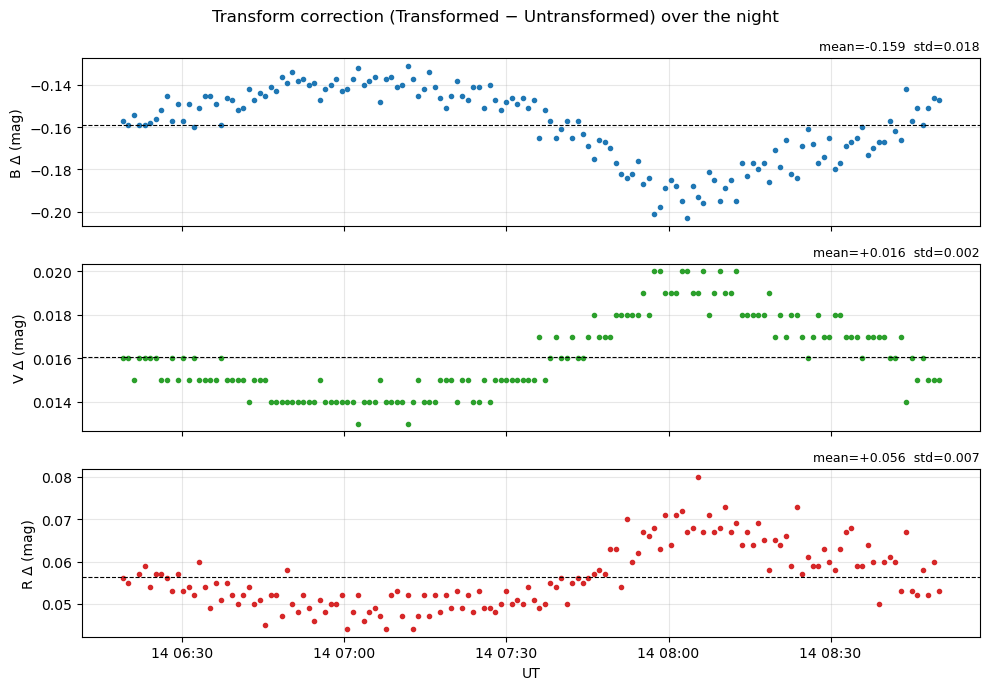

In [9]:
fig, axes = plt.subplots(3, 1, figsize=(10, 7), sharex=True)
for ax, filt in zip(axes, FILTER_ORDER):
    sub = merged[merged["FILT"] == filt].sort_values("UT_untrans")
    ax.plot(sub["UT_untrans"], sub["diff"], ".", color=FILTER_COLORS[filt])
    ax.axhline(sub["diff"].mean(), color="k", lw=0.8, ls="--")
    ax.set_ylabel(f"{filt} Δ (mag)")
    ax.set_title(f"mean={sub['diff'].mean():+.3f}  std={sub['diff'].std():.3f}", fontsize=9, loc="right")
    ax.grid(alpha=0.3)
axes[-1].set_xlabel("UT")
fig.suptitle("Transform correction (Transformed − Untransformed) over the night")
fig.tight_layout()

## 3. Check Star Quality Control

The check star should measure constant — comparing its derived standardized magnitude against its catalog
value (`KMAGSTD`/`KMAGTRAN` vs. `KREFMAG`) estimates the night's photometric precision and reveals any
airmass-dependent systematic error.

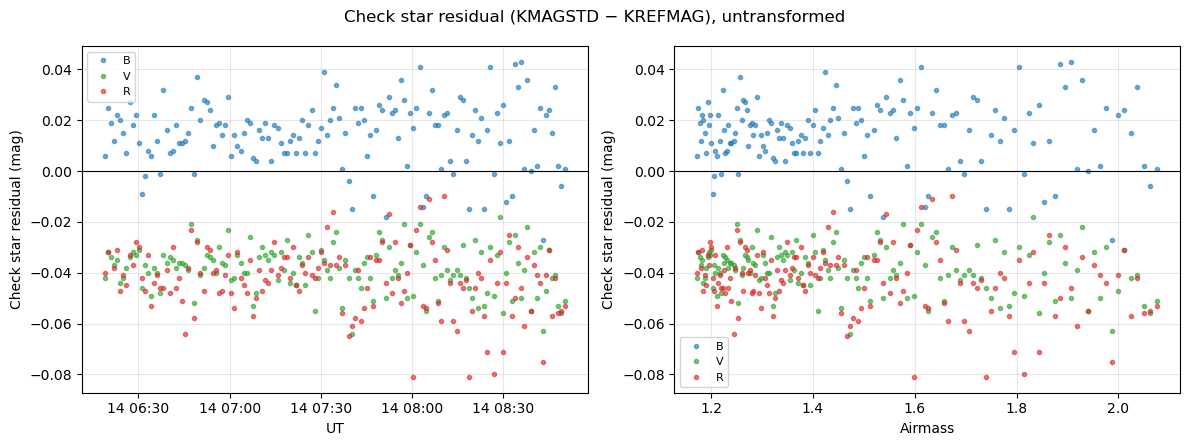

In [10]:
untrans_df["check_resid"] = untrans_df["KMAGSTD"] - untrans_df["KREFMAG"]
trans_df["check_resid"] = trans_df["KMAGTRAN"] - trans_df["KREFMAG"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for filt in FILTER_ORDER:
    u = untrans_df[untrans_df["FILT"] == filt]
    axes[0].plot(u["UT"], u["check_resid"], ".", color=FILTER_COLORS[filt], label=filt, alpha=0.6)
    axes[1].plot(u["AMASS"], u["check_resid"], ".", color=FILTER_COLORS[filt], label=filt, alpha=0.6)
axes[0].set_xlabel("UT"); axes[0].set_ylabel("Check star residual (mag)")
axes[1].set_xlabel("Airmass"); axes[1].set_ylabel("Check star residual (mag)")
for ax in axes:
    ax.axhline(0, color="k", lw=0.8)
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
fig.suptitle("Check star residual (KMAGSTD − KREFMAG), untransformed")
fig.tight_layout()

In [11]:
print("Untransformed check star residual:")
display(untrans_df.groupby("FILT")["check_resid"].agg(["count", "mean", "std"]).reindex(FILTER_ORDER))
print("\nTransformed check star residual:")
display(trans_df.groupby("FILT")["check_resid"].agg(["count", "mean", "std"]).reindex(FILTER_ORDER))

Untransformed check star residual:


,count,mean,std
FILT,,,
B,150,0.014500,0.012965
V,150,-0.038427,0.008998
R,149,-0.042752,0.012736



Transformed check star residual:


,count,mean,std
FILT,,,
B,150,0.017033,0.018256
V,150,-0.038707,0.009105
R,149,-0.043161,0.015994


## 4. Extinction & Observation Quality Diagnostics

Per-exposure diagnostics from the general export: signal quality vs. airmass, and focus/sky trends over the run.

Peak Max ADU this run: 8015 (check against sensor saturation/full-well level)


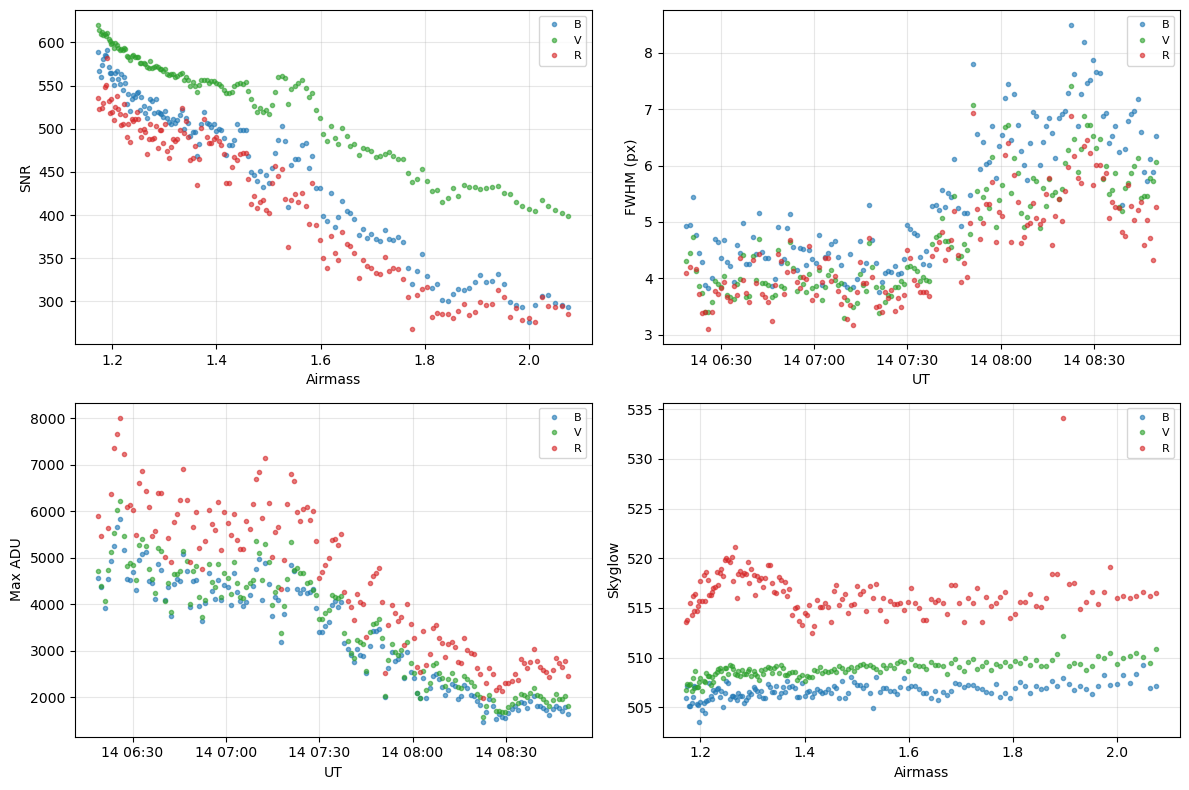

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for filt in FILTER_ORDER:
    g = general_df[general_df["Filter"] == filt]
    axes[0, 0].plot(g["Airmass"], g["SNR"], ".", color=FILTER_COLORS[filt], label=filt, alpha=0.6)
    axes[0, 1].plot(g["UT"], g["FWHM"], ".", color=FILTER_COLORS[filt], label=filt, alpha=0.6)
    axes[1, 0].plot(g["UT"], g["Max ADU"], ".", color=FILTER_COLORS[filt], label=filt, alpha=0.6)
    axes[1, 1].plot(g["Airmass"], g["Skyglow"], ".", color=FILTER_COLORS[filt], label=filt, alpha=0.6)
axes[0, 0].set_xlabel("Airmass"); axes[0, 0].set_ylabel("SNR")
axes[0, 1].set_xlabel("UT"); axes[0, 1].set_ylabel("FWHM (px)")
axes[1, 0].set_xlabel("UT"); axes[1, 0].set_ylabel("Max ADU")
axes[1, 1].set_xlabel("Airmass"); axes[1, 1].set_ylabel("Skyglow")
for ax in axes.flat:
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
fig.tight_layout()

print(f"Peak Max ADU this run: {general_df['Max ADU'].max()} (check against sensor saturation/full-well level)")

## 5. Summary

In [13]:
jd_start, jd_end = untrans_df["DATE"].min(), untrans_df["DATE"].max()
print(f"Run span: {jd_to_utc(pd.Series([jd_start])).iloc[0]} to {jd_to_utc(pd.Series([jd_end])).iloc[0]}"
      f"  ({(jd_end - jd_start) * 24:.2f} hours)")

summary = untrans_df.groupby("FILT").agg(
    n=("MAG", "size"),
    mag_min_untrans=("MAG", "min"), mag_max_untrans=("MAG", "max"),
    merr_mean=("MERR", "mean"),
    check_resid_mean_untrans=("check_resid", "mean"), check_resid_std_untrans=("check_resid", "std"),
).reindex(FILTER_ORDER)
summary_t = trans_df.groupby("FILT").agg(
    mag_min_trans=("MAG", "min"), mag_max_trans=("MAG", "max"),
    check_resid_mean_trans=("check_resid", "mean"), check_resid_std_trans=("check_resid", "std"),
).reindex(FILTER_ORDER)
summary = summary.join(summary_t)
summary

Run span: 2026-08-14 06:18:57.974394880+00:00 to 2026-08-14 08:50:06.000003328+00:00  (2.52 hours)


,n,mag_min_untrans,mag_max_untrans,merr_mean,check_resid_mean_untrans,check_resid_std_untrans,mag_min_trans,mag_max_trans,check_resid_mean_trans,check_resid_std_trans
FILT,,,,,,,,,,
B,150,10.696,11.227,0.002440,0.014500,0.012965,10.498,11.096,0.017033,0.018256
V,150,10.312,10.739,0.002147,-0.038427,0.008998,10.331,10.752,-0.038707,0.009105
R,149,10.096,10.471,0.002617,-0.042752,0.012736,10.160,10.523,-0.043161,0.015994


In [14]:
coeff_df = pd.DataFrame(coeffs, index=["value", "error"]).T
coeff_df

,value,error
Tbv,1.6847,0.0388
Tbr,1.5004,0.0165
Tvr,1.2362,0.0286
Tb_bv,0.3693,0.0181
Tb_br,0.2450,0.0113
Tv_vr,-0.0700,0.0352
Tv_bv,-0.0372,0.0173
Tr_vr,-0.2611,0.0306


In [15]:
print(f"Comparison star: {comp_id}  (catalog CREFMAG={untrans_df['CREFMAG'].iloc[0]})")
print(f"Check star:      {check_id}  (catalog KREFMAG={untrans_df['KREFMAG'].iloc[0]})")
print(f"Chart: {untrans_df['CHART'].iloc[0]}   OBSCODE: {untrans_header.get('OBSCODE')}   Software: {untrans_header.get('SOFTWARE')}")
print(f"Transform Applier version: {trans_df['TAver'].iloc[0]}")

Comparison star: 108  (catalog CREFMAG=10.819)
Check star:      111  (catalog KREFMAG=11.076)
Chart: X42985AK   OBSCODE: WJRA   Software: VPhot 4.0.83
Transform Applier version: 2.71
